# C07c — GLTR-feature classifier: OG vs NS10 and 20/34 adaptation

GLTR (Gehrmann et al., ACL 2019) is a human-facing visualization, not a released binary classifier. This experiment trains **our logistic classifier on its four rank-bin fractions** (ranks 1–10, 11–100, 101–1000, >1000), using frozen GPT-2 (124M, modern name for the original small model). It is not a reproduction of GLTR's human-subject accuracy. No NS11 or human subject text enters generation; this notebook only evaluates saved texts.

All 54 matched OG/NS10 cases use the exact C05 RAID membership and split. The classifier is fixed at C=1, balanced weights, with a train-only scaler. Adaptation refits on RAID train + 20 NS10 positives with that scaler frozen; the RAID-only control equals the original deterministic fit. The existing RoBERTa 20/34 split is reused when present, otherwise sampled once with seed 20260923 and saved.

**Memory:** GPT-2 FP32, one document at a time; first 1024 tokens, first token unscored, no artificial BOS. Logits are reduced in 32-position chunks. Prefix truncation is explicitly reported. Cache identity uses model revision, extraction settings and text only, never notebook code. Completed documents survive kernel restarts.

Run in a fresh kernel in `reproduction/`. Uses the existing torch/transformers/numpy/pandas/scikit-learn/matplotlib/pyarrow/huggingface_hub environment; no package downgrades.

References: https://aclanthology.org/P19-3019/ and https://github.com/HendrikStrobelt/detecting-fake-text


In [1]:
from pathlib import Path
import os, json, hashlib, tempfile, gc
import numpy as np
import pandas as pd
import torch, transformers
import matplotlib.pyplot as plt
from huggingface_hub import HfApi
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
import joblib
from IPython.display import display

ROOT_OVERRIDE = None
ROOT = Path(ROOT_OVERRIDE) if ROOT_OVERRIDE else next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p/'results/causal/C02d2_fz118_ghostbuster_raid').exists()), None)
assert ROOT is not None, 'Set ROOT_OVERRIDE to reproduction/.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C05=ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
NSDIR=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
OUT=ROOT/'results/causal/C07c_GLTR_RAID_OG_NS10_v1'
for sub in ['', 'features', 'figures']: (OUT/sub).mkdir(parents=True,exist_ok=True)
SEED=20260923
FEATURES=['rank_1_10','rank_11_100','rank_101_1000','rank_gt_1000']
def sha(x): return hashlib.sha256(str(x).encode()).hexdigest()
def atomic_json(path,value):
    path=Path(path); fd,tmp=tempfile.mkstemp(dir=path.parent,suffix='.tmp')
    try:
        with os.fdopen(fd,'w') as f:
            json.dump(value,f,indent=2,sort_keys=True,allow_nan=False); f.flush();os.fsync(f.fileno())
        os.replace(tmp,path)
    finally:
        if os.path.exists(tmp):os.unlink(tmp)
def freeze(path,value):
    if path.exists():
        if json.loads(path.read_text())!=value: raise ValueError(f'Experiment inputs changed: {path}')
    else:atomic_json(path,value)
print('Output:',OUT)


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Output: ../results/causal/C07c_GLTR_RAID_OG_NS10_v1


In [2]:
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].copy()
keys=pd.read_parquet(C05/'raid_all_features.parquet',columns=['doc_key']).doc_key
assert keys.is_unique and set(keys)==set('raid::'+raid.source_id.astype(str))
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
assert raid.text.notna().all() and raid.text.str.strip().ne('').all()
raid['text_sha']=raid.text.map(sha)
raid['pair_group']=raid.source_id.str.split('__',n=1).str[-1]
assert raid.groupby('pair_group').split.nunique().eq(1).all()
assert raid.groupby('text_sha').split.nunique().eq(1).all()
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
ns['case_id']=ns.case_id.astype(str)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(sha).eq(ns.text_sha).all()
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all() and rm.loc[ns.source_id,'label'].eq(1).all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text);og['text_sha']=og.text.map(sha)
tr=raid.loc[raid.split.eq('train')].sort_values('source_id').reset_index(drop=True)
va=raid.loc[raid.split.eq('validation')].sort_values('source_id').reset_index(drop=True)
te=raid.loc[raid.split.eq('test')].sort_values('source_id').reset_index(drop=True)
assert not set(ns.text_sha)&set(pd.concat([tr,va]).text_sha)
sp=OUT/'split.json'
prior=ROOT/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1/adaptation20_34_seed20260923/split.json'
if sp.exists():split=json.loads(sp.read_text())
elif prior.exists():
    old=json.loads(prior.read_text());split={k:old[k] for k in ['adaptation_cases','test_cases']};atomic_json(sp,split)
else:
    adapt=sorted(np.random.default_rng(SEED).choice(sorted(ns.case_id),20,replace=False).tolist())
    split={'adaptation_cases':adapt,'test_cases':sorted(set(ns.case_id)-set(adapt))};atomic_json(sp,split)
adapt_ids=list(map(str,split['adaptation_cases']));test_ids=list(map(str,split['test_cases']))
assert len(set(adapt_ids))==20 and len(set(test_ids))==34
assert not set(adapt_ids)&set(test_ids) and set(adapt_ids+test_ids)==set(ns.case_id)
raid.drop(columns='text').to_csv(OUT/'RAID_manifest.csv',index=False)
ns[['case_id','source_id','domain','text_sha']].to_csv(OUT/'NS10_manifest.csv',index=False)
display(raid.groupby(['split','label']).size().rename('documents').to_frame())
del meta,corpus,rm,keys;gc.collect()


documents
split      label           
test       0            138
           1            138
train      0            636
           1            636
validation 0            135
           1            135

40

In [3]:
# Restart-safe extraction. No language-model training.
pin_path=OUT/'model_pin.json'
if pin_path.exists():pin=json.loads(pin_path.read_text())
else:
    pin={'model':'openai-community/gpt2','revision':HfApi().model_info('openai-community/gpt2').sha}
    atomic_json(pin_path,pin)
spec={**pin,'max_tokens':1024,'dtype':'float32','first_token':'excluded','rank':'1 + number of strictly greater logits','version':1,'transformers':transformers.__version__,'torch':str(torch.__version__)}
freeze(OUT/'extractor.json',spec)
def feature_path(text):return OUT/'features'/(sha(json.dumps(spec,sort_keys=True)+sha(text))+'.json')
all_texts=list(dict.fromkeys(raid.text.tolist()+ns.text.tolist()))
pending=[t for t in all_texts if not feature_path(t).exists()]
print(f'{len(all_texts)-len(pending)}/{len(all_texts)} cached; {len(pending)} remaining',flush=True)
model=tok=None
try:
    if pending:
        device='cuda' if torch.cuda.is_available() else 'cpu'
        tok=AutoTokenizer.from_pretrained(pin['model'],revision=pin['revision'])
        model=AutoModelForCausalLM.from_pretrained(pin['model'],revision=pin['revision'],torch_dtype=torch.float32,attn_implementation='eager').to(device).eval()
    for i,text in enumerate(pending,1):
        ids=tok.encode(text,add_special_tokens=False,truncation=False)
        total=len(ids);ids=ids[:1024]
        if len(ids)<2:raise ValueError('Document has fewer than two GPT-2 tokens: '+sha(text))
        batch=torch.tensor([ids],device=device)
        counts=np.zeros(4,dtype=np.int64)
        with torch.inference_mode():
            logits=model(input_ids=batch,use_cache=False).logits[0,:-1]
            for start in range(0,len(ids)-1,32):
                z=logits[start:start+32].float()
                target=batch[0,start+1:start+1+len(z)]
                actual=z.gather(1,target[:,None])
                ranks=1+(z>actual).sum(dim=1)
                counts+=np.array([(ranks<=10).sum().item(),((ranks>10)&(ranks<=100)).sum().item(),((ranks>100)&(ranks<=1000)).sum().item(),(ranks>1000).sum().item()])
            del logits,z,target,actual,ranks,batch
        assert counts.sum()==len(ids)-1
        record={'text_sha':sha(text),'total_tokens':total,'scored_tokens':len(ids)-1,'truncated':total>1024,**dict(zip(FEATURES,(counts/counts.sum()).tolist()))}
        atomic_json(feature_path(text),record)
        if i%10==0 or i==len(pending):print(f'{i}/{len(pending)} newly saved',flush=True)
finally:
    del model,tok;gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
def augment(frame):
    records=[json.loads(feature_path(t).read_text()) for t in frame.text]
    return pd.concat([frame.reset_index(drop=True).drop(columns='text_sha',errors='ignore'),pd.DataFrame(records)],axis=1)
trf,vaf,tef,ogf,nsf=map(augment,[tr,va,te,og,ns])
for name,frame in [('RAID_train',trf),('RAID_validation',vaf),('RAID_test',tef),('OG',ogf),('NS10',nsf)]:
    frame.drop(columns='text').to_csv(OUT/(name+'_features.csv'),index=False)
    print(name,':',len(frame),'documents;',int(frame.truncated.sum()),'prefix-truncated')


0/1872 cached; 1872 remaining
10/1872 newly saved
20/1872 newly saved
30/1872 newly saved
40/1872 newly saved
50/1872 newly saved
60/1872 newly saved
70/1872 newly saved
80/1872 newly saved
90/1872 newly saved
100/1872 newly saved
110/1872 newly saved
120/1872 newly saved
130/1872 newly saved
140/1872 newly saved
150/1872 newly saved
160/1872 newly saved
170/1872 newly saved
180/1872 newly saved
190/1872 newly saved
200/1872 newly saved
210/1872 newly saved
220/1872 newly saved
230/1872 newly saved
240/1872 newly saved
250/1872 newly saved
260/1872 newly saved
270/1872 newly saved
280/1872 newly saved
290/1872 newly saved
300/1872 newly saved
310/1872 newly saved
320/1872 newly saved
330/1872 newly saved
340/1872 newly saved
350/1872 newly saved
360/1872 newly saved
370/1872 newly saved
380/1872 newly saved
390/1872 newly saved
400/1872 newly saved
410/1872 newly saved
420/1872 newly saved
430/1872 newly saved
440/1872 newly saved
450/1872 newly saved
460/1872 newly saved
470/1872 newl

In [4]:
# Fixed settings: no attack-based hyperparameter or threshold selection.
scaler=StandardScaler().fit(trf[FEATURES])
def fit_head(frame):
    return LogisticRegression(C=1.,class_weight='balanced',solver='lbfgs',max_iter=5000,random_state=SEED).fit(scaler.transform(frame[FEATURES]),frame.label.astype(int))
frozen=fit_head(trf)
control=fit_head(trf)
assert np.allclose(frozen.coef_,control.coef_) and np.allclose(frozen.intercept_,control.intercept_)
adapt20=nsf.set_index('case_id').loc[adapt_ids].reset_index().assign(label=1)
adapted=fit_head(pd.concat([trf,adapt20],ignore_index=True))
heads={'Frozen / RAID-only':frozen,'NS10-adapted':adapted}
joblib.dump({'scaler':scaler,'heads':heads,'features':FEATURES,'split':split,'extractor':spec},OUT/'classifiers.joblib')
manifest={'C':1.,'class_weight':'balanced','solver':'lbfgs','seed':SEED,'split':split,'train_text_sha':trf.text_sha.tolist(),'adapt_text_sha':adapt20.text_sha.tolist()}
freeze(OUT/'classifier_inputs.json',manifest)
def score(head,frame):return head.decision_function(scaler.transform(frame[FEATURES]))
print('Regular RAID test AUROC:',roc_auc_score(tef.label,score(frozen,tef)))
pd.DataFrame([{'detector':'Frozen / RAID-only','split':'test','AUROC':roc_auc_score(tef.label,score(frozen,tef))}]).to_csv(OUT/'regular_RAID_summary.csv',index=False)
display(pd.DataFrame({name:head.coef_[0] for name,head in heads.items()},index=FEATURES))


Regular RAID test AUROC: 0.8272946859903381


,Frozen / RAID-only,NS10-adapted
rank_1_10,0.405674,0.401549
rank_11_100,-0.109481,-0.137862
rank_101_1000,-0.465140,-0.465488
rank_gt_1000,-0.673934,-0.587407


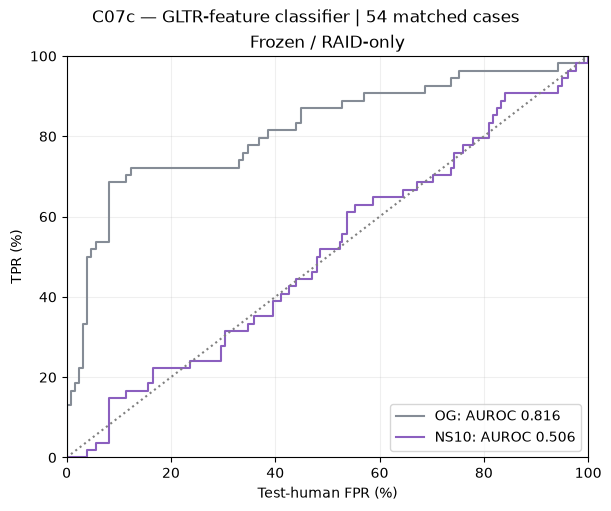

,detector,arm,cases,AUROC,mean_log_odds
0,Frozen / RAID-only,OG,54,0.8160,0.6505
1,Frozen / RAID-only,NS10,54,0.5062,-0.6968


,detector,arm,nominal_FPR,threshold,test_FPR,TPR
0,Frozen / RAID-only,OG,0.010,1.6527,0.0079,0.1296
1,Frozen / RAID-only,OG,0.025,1.4890,0.0159,0.1852
2,Frozen / RAID-only,OG,0.050,1.2895,0.0317,0.2778
3,Frozen / RAID-only,OG,0.100,0.7967,0.0813,0.5926
4,Frozen / RAID-only,OG,0.200,0.3532,0.1652,0.7222
5,Frozen / RAID-only,OG,0.500,-0.5024,0.4706,0.8704
6,Frozen / RAID-only,NS10,0.010,1.6527,0.0079,0.0000
7,Frozen / RAID-only,NS10,0.025,1.4890,0.0159,0.0000
8,Frozen / RAID-only,NS10,0.050,1.2895,0.0317,0.0000
9,Frozen / RAID-only,NS10,0.100,0.7967,0.0813,0.0556


,comparison,AUROC_delta,ci_low,ci_high
0,"('Frozen / RAID-only', 'NS10') minus ('Frozen ...",-0.3097,-0.3861,-0.2344


Intervals: case resampling only; fixed humans/models; no seed or split uncertainty.


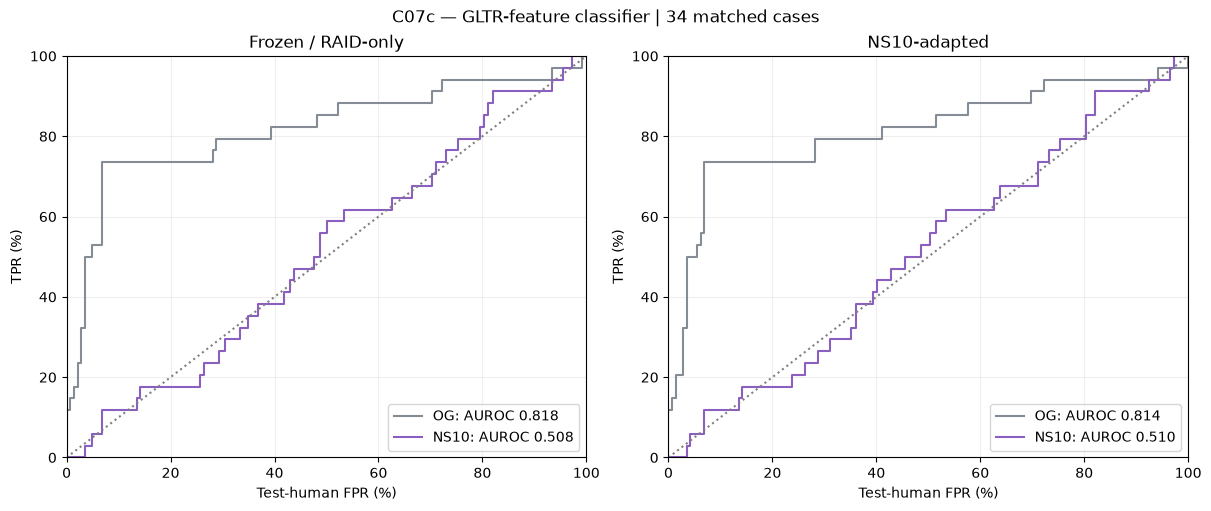

,detector,arm,cases,AUROC,mean_log_odds
0,Frozen / RAID-only,OG,34,0.8178,0.5814
1,Frozen / RAID-only,NS10,34,0.5083,-0.7867
2,NS10-adapted,OG,34,0.8145,0.5781
3,NS10-adapted,NS10,34,0.5099,-0.7156


,detector,arm,nominal_FPR,threshold,test_FPR,TPR
0,Frozen / RAID-only,OG,0.010,1.6527,0.0070,0.1176
1,Frozen / RAID-only,OG,0.025,1.4890,0.0140,0.1765
2,Frozen / RAID-only,OG,0.050,1.2271,0.0350,0.3235
3,Frozen / RAID-only,OG,0.100,0.7114,0.0678,0.7059
4,Frozen / RAID-only,OG,0.200,0.2228,0.2074,0.7353
5,Frozen / RAID-only,OG,0.500,-0.5510,0.4373,0.8235
6,Frozen / RAID-only,NS10,0.010,1.6527,0.0070,0.0000
7,Frozen / RAID-only,NS10,0.025,1.4890,0.0140,0.0000
8,Frozen / RAID-only,NS10,0.050,1.2271,0.0350,0.0000
9,Frozen / RAID-only,NS10,0.100,0.7114,0.0678,0.0882


,comparison,AUROC_delta,ci_low,ci_high
0,"('Frozen / RAID-only', 'NS10') minus ('Frozen ...",-0.3095,-0.4015,-0.2203
1,"('NS10-adapted', 'NS10') minus ('NS10-adapted'...",-0.3045,-0.3977,-0.2138
2,"('NS10-adapted', 'NS10') minus ('Frozen / RAID...",0.0016,-0.0026,0.0058


Intervals: case resampling only; fixed humans/models; no seed or split uncertainty.


In [5]:
# TPR staircases with matched genre-weighted humans and validation thresholds.
def human_weights(frame,mix):
    counts=frame.domain.value_counts()
    assert set(mix.index)<=set(counts.index)
    w=np.array([mix[d]/counts[d] for d in frame.domain]);assert np.isclose(w.sum(),1)
    return w
def auc_fixed_humans(a,h,w):
    return (((a[:,None]>h).astype(float)+.5*(a[:,None]==h))@w).mean()
def evaluate(ids,names,tag):
    arms={'OG':ogf.set_index('case_id').loc[ids].reset_index(),'NS10':nsf.set_index('case_id').loc[ids].reset_index()}
    mix=arms['OG'].domain.value_counts(normalize=True)
    humans=tef.loc[tef.label.eq(0)&tef.domain.isin(mix.index)]
    cal=vaf.loc[vaf.label.eq(0)&vaf.domain.isin(mix.index)]
    w=human_weights(humans,mix);cw=human_weights(cal,mix)
    fig,axes=plt.subplots(1,len(names),figsize=(6*len(names),5),squeeze=False,constrained_layout=True)
    rows=[];points=[];saved=[];stairs=[];arrays={};human_arrays={}
    for ax,name in zip(axes[0],names):
        head=heads[name];h=score(head,humans);c=score(head,cal);human_arrays[name]=h
        for arm,color in [('OG','#858C96'),('NS10','#8B5FBF')]:
            frame=arms[arm];a=score(head,frame);arrays[(name,arm)]=a
            auc=auc_fixed_humans(a,h,w)
            y=np.r_[np.zeros(len(h)),np.ones(len(a))];s=np.r_[h,a]
            fp,tp,thresholds=roc_curve(y,s,sample_weight=np.r_[w,np.ones(len(a))/len(a)],drop_intermediate=False)
            ax.step(fp*100,tp*100,where='post',color=color,label=f'{arm}: AUROC {auc:.3f}')
            rows.append(dict(detector=name,arm=arm,cases=len(a),AUROC=auc,mean_log_odds=a.mean()))
            stairs.extend(dict(detector=name,arm=arm,FPR=float(x),TPR=float(y),threshold=float(t)) for x,y,t in zip(fp,tp,thresholds))
            saved.extend(dict(detector=name,arm=arm,case_id=cid,AI_log_odds=float(v)) for cid,v in zip(frame.case_id,a))
            for target in [.01,.025,.05,.10,.20,.50]:
                cuts=np.r_[np.inf,np.unique(c)]
                cut=min(t for t in cuts if cw[c>=t].sum()<=target+1e-12)
                points.append(dict(detector=name,arm=arm,nominal_FPR=target,threshold=cut,test_FPR=w[h>=cut].sum(),TPR=(a>=cut).mean()))
        saved.extend(dict(detector=name,arm='Human',case_id=str(cid),AI_log_odds=float(v)) for cid,v in zip(humans.source_id,h))
        ax.plot([0,100],[0,100],':',color='gray');ax.set(xlim=(0,100),ylim=(0,100),xlabel='Test-human FPR (%)',ylabel='TPR (%)',title=name);ax.grid(alpha=.2);ax.legend(loc='lower right')
    fig.suptitle(f'C07c — GLTR-feature classifier | {len(ids)} matched cases')
    for ext in ['png','pdf']:fig.savefig(OUT/'figures'/f'{tag}.{ext}',dpi=220)
    plt.show();plt.close(fig)
    for suffix,data in [('summary',rows),('operating_points',points),('scores',saved),('staircases',stairs)]:pd.DataFrame(data).to_csv(OUT/f'{tag}_{suffix}.csv',index=False)
    display(pd.DataFrame(rows).round(4));display(pd.DataFrame(points).round(4))
    # Paired case bootstrap, fixed fitted models and fixed human references.
    rng=np.random.default_rng(SEED);draw=rng.integers(0,len(ids),(5000,len(ids)))
    contrasts=[((name,'NS10'),(name,'OG')) for name in names]
    if len(names)>1:contrasts.append(((names[1],'NS10'),(names[0],'NS10')))
    changes=[]
    for right,left in contrasts:
        def per_case(key):
            a=arrays[key];h=human_arrays[key[0]]
            return ((a[:,None]>h).astype(float)+.5*(a[:,None]==h))@w
        d=per_case(right)-per_case(left);boot=d[draw].mean(axis=1);lo,hi=np.quantile(boot,[.025,.975])
        changes.append(dict(comparison=str(right)+' minus '+str(left),AUROC_delta=d.mean(),ci_low=lo,ci_high=hi))
    pd.DataFrame(changes).to_csv(OUT/f'{tag}_paired_changes.csv',index=False);display(pd.DataFrame(changes).round(4))
    print('Intervals: case resampling only; fixed humans/models; no seed or split uncertainty.')
    return arrays,human_arrays,w
all54=evaluate(ns.case_id.tolist(),['Frozen / RAID-only'],'GLTR_OG_NS10_54')
held34=evaluate(test_ids,['Frozen / RAID-only','NS10-adapted'],'GLTR_adaptation20_34')


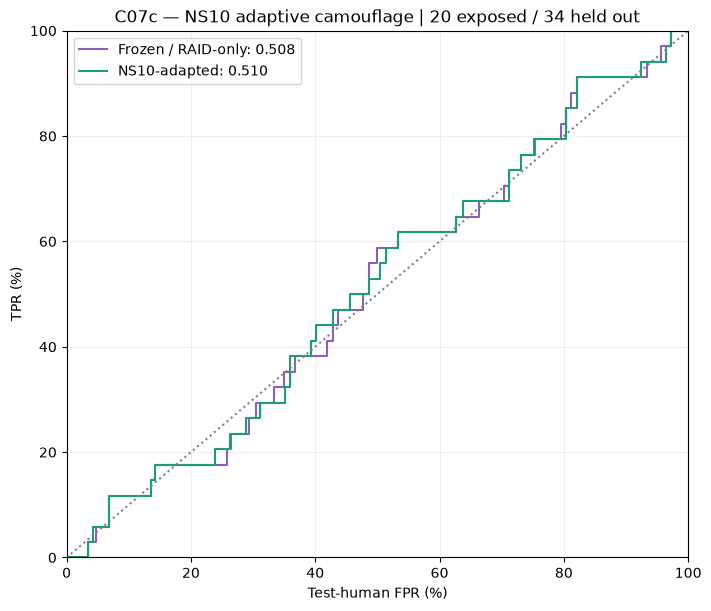

Saved all outputs: ../results/causal/C07c_GLTR_RAID_OG_NS10_v1
C07d is reserved for a separate detector evaluation; no paid API calls are made here.


In [6]:
# Direct adaptation overlay: identical 34 NS10 cases and human references.
arrays,hs,w=held34
fig,ax=plt.subplots(figsize=(7,6),constrained_layout=True)
for name,color in [('Frozen / RAID-only','#8B5FBF'),('NS10-adapted','#1B9E77')]:
    a=arrays[(name,'NS10')];h=hs[name]
    fp,tp,_=roc_curve(np.r_[np.zeros(len(h)),np.ones(len(a))],np.r_[h,a],sample_weight=np.r_[w,np.ones(len(a))/len(a)],drop_intermediate=False)
    ax.step(100*fp,100*tp,where='post',color=color,label=f'{name}: {auc_fixed_humans(a,h,w):.3f}')
ax.plot([0,100],[0,100],':',color='gray');ax.set(xlim=(0,100),ylim=(0,100),xlabel='Test-human FPR (%)',ylabel='TPR (%)',title='C07c — NS10 adaptive camouflage | 20 exposed / 34 held out');ax.grid(alpha=.2);ax.legend()
for ext in ['png','pdf']:fig.savefig(OUT/'figures'/f'GLTR_adaptation_overlay34.{ext}',dpi=220)
plt.show();plt.close(fig)
print('Saved all outputs:',OUT)
print('C07d is reserved for a separate detector evaluation; no paid API calls are made here.')
